In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data

In [ ]:
def mostrar(img, titulos, cmap='gray', tamanho=4):
  n = len(img)
  plt.figure(figsize=(tamanho*n, tamanho))
  for i in range(n):
    plt.subplot(1, n, i+1)
    plt.imshow(img[i], cmap=cmap)
    plt.title(titulos[i])
    plt.axis('off')
  plt.show()

In [ ]:
gato = data.cat()
cafe = data.coffee()

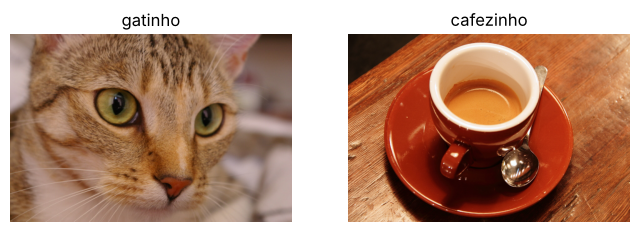

In [ ]:
mostrar([gato, cafe], ['gatinho', 'cafezinho'])

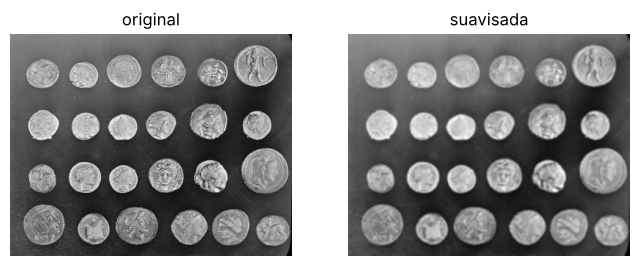

In [ ]:
moedas = data.coins()
moedas_suave = cv2.GaussianBlur(moedas, (5, 5), 0)
mostrar([moedas, moedas_suave], ['original', 'suavisada'])

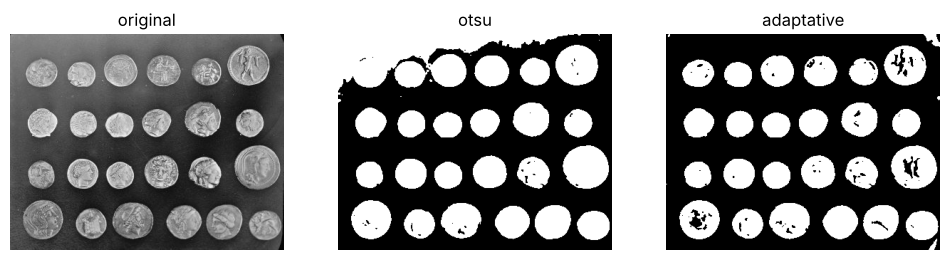

In [ ]:
_, moedas_otsu = cv2.threshold(moedas_suave,
                             0,
                             255,
                             cv2.THRESH_OTSU)
moedas_adapt = cv2.adaptiveThreshold(moedas_suave,
                                   255,
                                   cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY,
                                   101,
                                   -10)

mostrar([moedas, moedas_otsu, moedas_adapt], ['original', 'otsu', 'adaptative'])

In [ ]:
contornos, _ = cv2.findContours(moedas_adapt,
                              cv2.RETR_EXTERNAL,
                              cv2.CHAIN_APPROX_SIMPLE)
contornos = [c for c in contornos if cv2.contourArea(c) > 500]
print('Quantidade de contornos: ', len(contornos))

Quantidade de contornos:  24


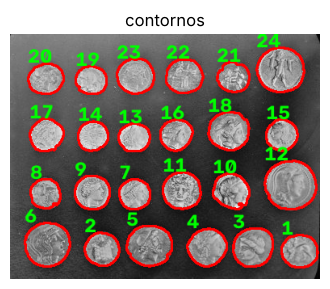

In [ ]:
saida = cv2.cvtColor(moedas, cv2.COLOR_GRAY2RGB)
cv2.drawContours(saida, contornos, -1, (255, 0, 0), 2)

for i, c in enumerate(contornos):
  x, y, w, h = cv2.boundingRect(c)
  cv2.putText(saida, str(i+1), (x, y), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)

mostrar([saida], ['contornos'])

# Desafio portfólio: segmentação semântica × segmentação por instância


In [ ]:
def segmentar(img, bloco=101, C=-10, area_min=500):
  suave = cv2.GaussianBlur(img, (5, 5), 0)
  binaria = cv2.adaptiveThreshold(suave, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                  cv2.THRESH_BINARY, bloco, C)
  contornos, _ = cv2.findContours(binaria, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
  contornos = [c for c in contornos if cv2.contourArea(c) > area_min]

  semantica = np.zeros(img.shape, dtype=np.uint8)
  rotulos = np.zeros(img.shape, dtype=np.int32)
  for i, c in enumerate(contornos):
    cv2.drawContours(semantica, [c], -1, 255, cv2.FILLED)
    cv2.drawContours(rotulos, [c], -1, i + 1, cv2.FILLED)

  return semantica, rotulos, len(contornos)


def colorir_instancias(rotulos, n, semente=0):
  rng = np.random.default_rng(semente)
  cores = (plt.cm.hsv(np.linspace(0, 1, n, endpoint=False))[:, :3] * 255).astype(np.uint8)
  cores = cores[rng.permutation(n)]
  saida = np.zeros((*rotulos.shape, 3), dtype=np.uint8)
  for i in range(n):
    saida[rotulos == i + 1] = cores[i]
  return saida


def comparar(img, nome, **params):
  semantica, rotulos, n = segmentar(img, **params)
  instancia = colorir_instancias(rotulos, n)
  print(f'{nome}: {n} instâncias encontradas')
  plt.figure(figsize=(15, 4))
  for i, (im, titulo, cmap) in enumerate([
      (img, 'Entrada', 'gray'),
      (semantica, f'Semântica (1 classe: {nome})', 'gray'),
      (instancia, f'Instância (1 cor por {nome})', None)]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(im, cmap=cmap)
    plt.title(titulo)
    plt.axis('off')
  plt.show()
  return semantica, rotulos, n

## Imagem 1: `data.coins()`

moeda: 24 instâncias encontradas


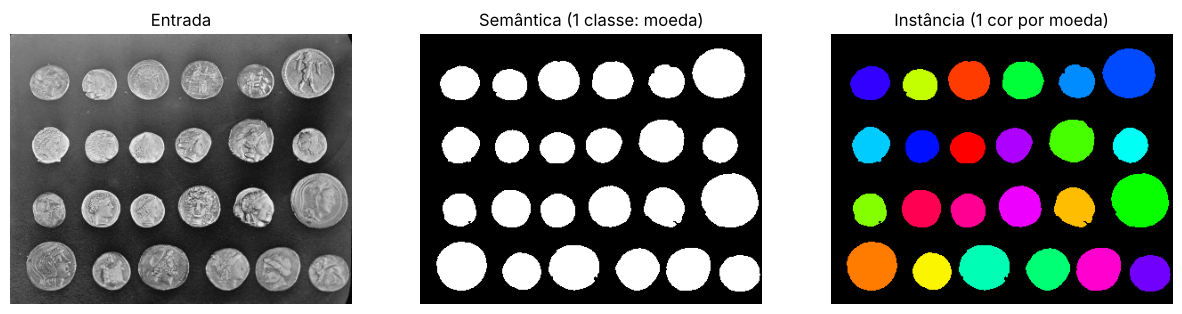

In [ ]:
sem_moedas, rot_moedas, n_moedas = comparar(moedas, 'moeda', bloco=101, C=-10, area_min=500)

## Imagem do telescópio Hubble



galáxia: 172 instâncias encontradas


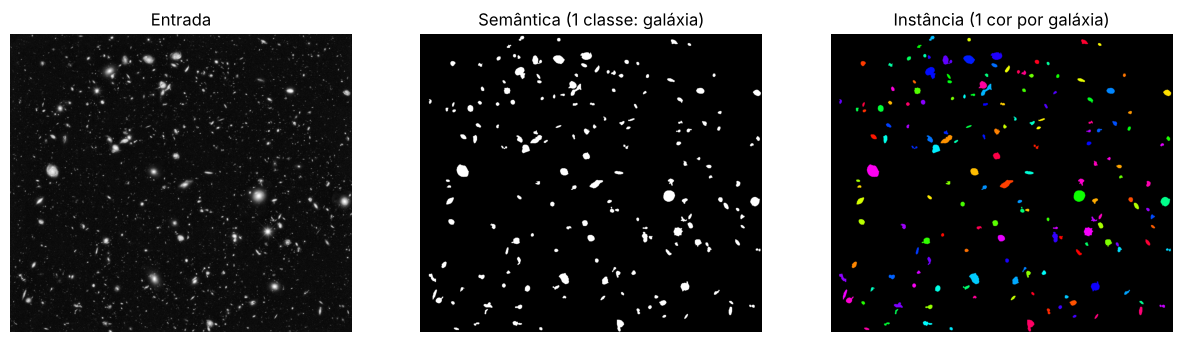

In [ ]:
hubble = cv2.cvtColor(data.hubble_deep_field(), cv2.COLOR_RGB2GRAY)
sem_hubble, rot_hubble, n_hubble = comparar(hubble, 'galáxia', bloco=101, C=-20, area_min=50)

## Análise

**Moedas:** a segmentação funcionou bem nas duas formas. As 24 moedas estão separadas por fundo escuro, então cada mancha branca da máscara semântica corresponde exatamente a uma moeda, e a instância só "pinta" cada uma de uma cor. Aqui as duas segmentações carregam quase a mesma informação; a vantagem da instância é poder contar e medir cada moeda individualmente.

**Hubble:** houve diferença clara. Os objetos são pequenos, muito numerosos e com brilho variado, então:
- galáxias fracas ou muito pequenas somem
- galáxias que se sobrepõem ou encostam viram **uma única instância**, porque o método separa objetos apenas por contornos desconectados;

**Conclusão:** limiar + contornos produz uma boa segmentação por instância só quando os objetos estão isolados entre si (caso das moedas). Para objetos que se tocam, seria necessário algo como *watershed* com transformada de distância ou um modelo de deep learning.